# Stock feature ablation

Five feature sets, 96 expanding-fit dates and 94 mature evaluation months. All observations come from the supplied market archive. These are development rank correlations, not investment returns.

In [1]:
from pathlib import Path
import json, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
root=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'pyproject.toml').exists())
study=root/'reports/stock_feature_ablation_v1'
sha=lambda p:hashlib.sha256(p.read_bytes()).hexdigest()
manifest=json.loads((study/'export-manifest.json').read_text())
assert (study/'COMPLETE').read_text().strip()==sha(study/'export-manifest.json')
assert manifest['complete'] and not manifest['holdout_evaluated']
for name,digest in manifest['outputs_sha256'].items():
    assert sha(study/name)==digest
metrics=pd.DataFrame(json.loads((study/'metrics.json').read_text()))
paired=json.loads((study/'paired-comparison.json').read_text())
audit=json.loads((study/'audit-summary.json').read_text())
assert audit['scientific_assertions_PASS'] and audit['independent_metric_cells']==480
assert len(metrics)==480 and not metrics.duplicated(['signal_session','arm_id']).any()
display(metrics.groupby(['arm_id','status']).size().unstack(fill_value=0))

status,insufficient_resolved_cross_section,valid
arm_id,,
activity,2,94
all_features,2,94
momentum_trend,2,94
reversal,2,94
risk,2,94


## Common evaluation months

Use the same mature months for every arm. The final two development months remain recorded but do not contribute unavailable outcomes.

,mean,median,std,positive_month_fraction,difference_from_all_features
arm_id,,,,,
all_features,0.008557,0.012471,0.080718,0.585106,0.000000
momentum_trend,0.008273,0.015987,0.068436,0.563830,-0.000284
activity,0.008039,0.017742,0.082312,0.553191,-0.000518
reversal,0.003697,0.010910,0.088373,0.563830,-0.004860
risk,0.002461,0.001544,0.080344,0.510638,-0.006095


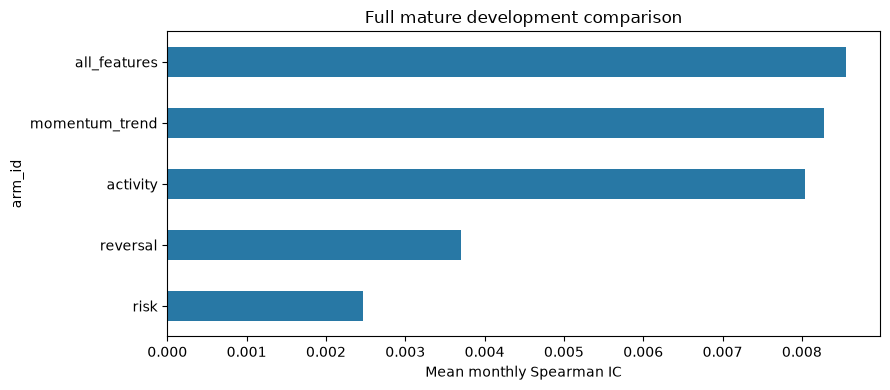

In [2]:
dates=paired["common_mature_dates"]
assert len(dates)==94
wide=metrics[metrics.signal_session.isin(dates)].pivot(index="signal_session",columns="arm_id",values="ic").sort_index()
assert wide.shape==(94,5) and wide.notna().all().all()
summary=wide.agg(["mean","median","std"]).T
summary["positive_month_fraction"]=wide.gt(0).mean()
summary["difference_from_all_features"]=summary["mean"]-summary.loc["all_features","mean"]
display(summary.sort_values("mean",ascending=False))
fig,ax=plt.subplots(figsize=(9,4))
summary["mean"].sort_values().plot.barh(ax=ax,color="#2878a5")
ax.axvline(0,color="black",lw=.7);ax.set(xlabel="Mean monthly Spearman IC",title="Full mature development comparison")
fig.tight_layout();plt.show()

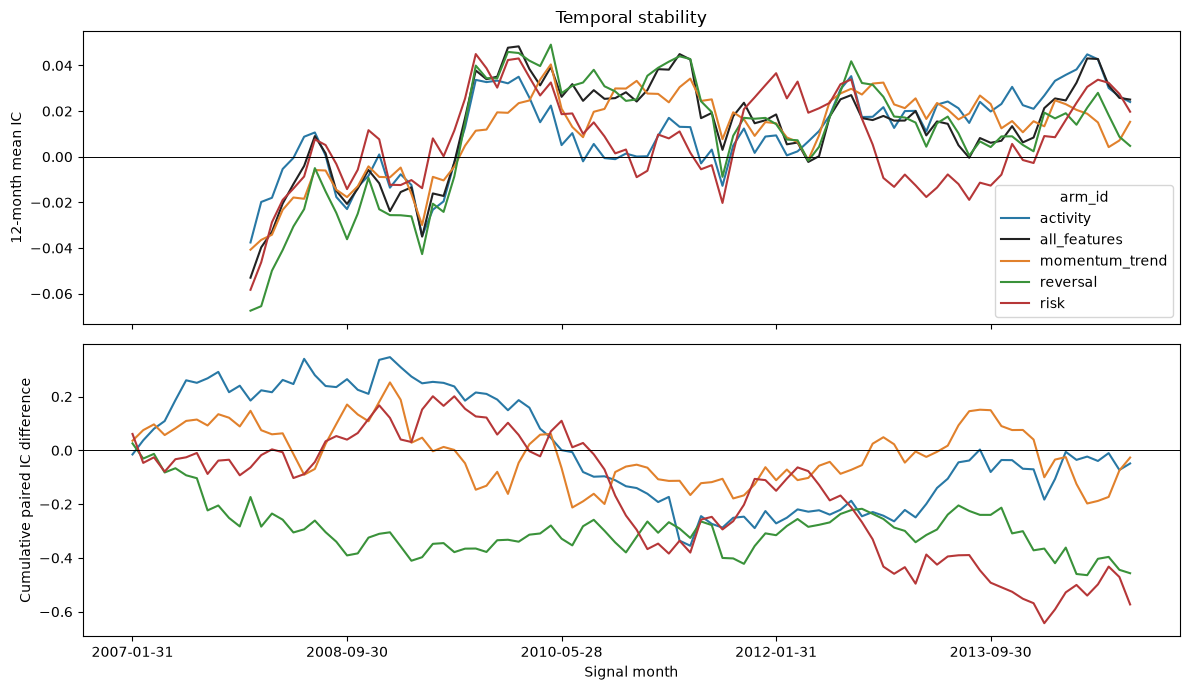

In [3]:
fig,axes=plt.subplots(2,1,figsize=(12,7),sharex=True)
colors={"activity":"#2878a5","all_features":"#222222","momentum_trend":"#e1812c","reversal":"#3a923a","risk":"#b63738"}
wide.rolling(12,min_periods=12).mean().plot(ax=axes[0],color=colors)
axes[0].axhline(0,color="black",lw=.7);axes[0].set(ylabel="12-month mean IC",title="Temporal stability")
deltas=wide.drop(columns="all_features").subtract(wide.all_features,axis=0)
deltas.cumsum().plot(ax=axes[1],legend=False,color=colors)
axes[1].axhline(0,color="black",lw=.7);axes[1].set(ylabel="Cumulative paired IC difference",xlabel="Signal month")
fig.tight_layout();plt.show()

## Interpretation

The full feature set retains the highest average IC. Removing any tested feature family reduces it. This ablation does not establish a trading edge or independent test performance. The audit checked all 480 prediction/fit cells and reconstructed training inputs. Its original process reached the final receipt with a metadata-key error; the receipt repair is recorded explicitly, with the original traceback retained.